# Ash3d


Ash3d is a 3-D Eulerian model to predict airborne volcanic ash concentration
and tephra deposition during volcanic eruptions. 

### References & Examples

User Guide (USGS): Mastin, L.G., Randall, M.J., Schwaiger, H.F., and Denlinger, R.P., 2021, User’s guide and reference to the web interface of Ash3d—A three-dimensional model for Eulerian atmospheric tephra transport and deposition (ver. 2.0, April 2021): U.S. Geological Survey Open-File Report 2013–1122, 25 p., https://doi.org/10.3133/ofr20131122.

Mastin LG, Van Eaton AR, Schwaiger HF (2020) A probabilistic assessment of tephra-fall hazards at Hanford, Washington, from a future eruption of Mount St. Helens. In: Open-File Report. Reston, VA, p 54

### Required installed libraries for this workflow

In [9]:
import sys
import rioxarray as rxr
import subprocess

### General source and I/O params

In [10]:
# Volcano name (character*30) for searching db
volc_name = "St. Helens 1980"

# Name of output file
output_file = "3d_tephra_fall.nc"

# Title of simulation
title = "Mount St. Helens 1980"

# Proj flags and params; first term (LLflag) is 1, so all else ignore
# NOTE: If the computational grid is projected (first value is 0), 
# please refer to the documentation to properly enter values
proj_and_params = "1 4 -107.0 50.0 50.0 50.0 6367.470"

# x, y of LL corner of grid (km, or deg. if latlongflag=1)
xll = -124.0
yll = 42.0 

# grid width and height (km, or deg. if latlonflag=1)
grid_width = 14.0
grid_height = 7.0 

# vent location         (km, or deg. if latlonflag=1)
vent_long = -122.18
vent_lat = 46.20 

# DX, DY of grid cells  (km, or deg. if latlonflag=1)
dx = 0.10
dy = 0.10

# DZ of grid cells      (always km)
dz = 1.0

# diffusion coefficient (m2/s), Suzuki constant
diff_coeff = 0
suzuki = 8.0

### For each eruption/pulse, you must enter data as described below.

In [11]:
# neruptions, number of eruptions or pulses
neruptions = 14

year = '1980'

month = '05'

day = [ '18', '18', '18', '18', '18', '18', '18', '18', '18', '18', '18', '18', '19', '19']

time = ['15.50', '16.00', '16.60', '17.50', '18.25', '18.75', '19.25', '19.75', '20.25', '21.25', '22.50', '23.50', '00.50', '01.50']

#Duration (in hours)
duration = ['0.50', '0.11', '0.90', '0.75', '0.50', '0.50', '0.50', '0.50', '1.00', '1.25', '1.00', '1.00', '1.00', '1.00']

#Plume Height (kilometers)
plume_height = [ 25.0, 15.3, 13.7, 15.3, 16.1, 17.4, 17.4, 13.5, 14.6, 14.7, 15.8, 19.2, 7.7 , 6.2]

#Erupted Volume (kilometers cubed)
volume = [0.0649, 0.0015, 0.0071, 0.0100, 0.0085, 0.0123, 0.0123, 0.0037, 0.0107, 0.0138, 0.0156, 0.0389, 0.0004, 0.0001]

### Now, lets specify where the wind data will come from

### iwind:
1. read from a 1-D wind sounding                                                         
2. read from 3D gridded ASCII files                                                      
3.  4. read directly from a single or multiple NetCDF files.                               
5. read directly from multiple multi-timestep NetCDF files.

The format has over 30 options. We will default to the 2.5 NCAR reanalysis data. Users who require other approaches can go here LINK HERE

The iHeightHandler variable accounts for the plume reaching mesoscale heights as follows:
1. Stop the program if the plume height exceeds mesoscale height
2. Set wind velocity at levels above the highest node equal that of the highest node.

In [12]:
# iwind, iwindformat
iwind, iwindformat = 5, 25

# iHeightHandler
iheighthandler = 2
# Simulation time in hours
sim_time = 12
# stop computation when 99% of erupted mass has deposited?
stop_comp = True
# nWindFiles, number of gridded wind files (used if iwind>1)
nwindfiles = 1

### Below, please enter a few values relevant to grain size calculations

In [13]:
# grain size (mm)
grain_size = .5

#mass fraction
mass_frac = 1

#density (kg/m3)
density = 2624

### Time to specify some output file related parameters.

Specify if you want:
1. An ascii/kmz file of final deposit thickness                   
2. ascii/kmz deposit files at specified times                 
3. ascii/kmz files of ash-cloud concentration
4. ascii/kmz files of ash-cloud height
5. ascii/kmz files of ash-cloud load (T/km2) at specified times
6. An ascii/kmz file of deposit arrival times
7. An ascii/kmzfile of cloud arrival times

Additionally, please specify if you want to:
- Write out 3-D ash concentration at specified times
- format of ash concentration files (ascii, binary, or netcdf)                             
- The total number of times to write outputs, and their values

In [14]:
ascii_output_files = [True, False, False, False, False, False, True]

kmz_output_files = [False, False, False, False, False, False, True]

In [15]:
ash_conc_output = False

output_format = "netcdf"

n_write = 8

write_times = "9.1 20.2 32.3 43.3 55.2 64.6 78.2 89.5"

### Next, you can specify whether you want times of ash arrival at airports and other locations

In [16]:
# Write out ash arrival times at airports to ASCII file?
arrival_times_asc = True
# Write out grain-size distribution to ASCII airport 
gsd = False
# Write out ash arrival times to kml file?
arrival_times_kml = False
# Name of file containing airport locations
location_file = 'MSH_sample_locations.txt'
# Have libprojection calculate projected coordinates?
calc_projected = False

In [35]:
newline = '\n'
inp = f"""# The following is an input file to the model Ash3d, v.1.0                                             
# Created by L.G. Mastin, R.P. Denlinger and H.F. Schwaiger, U.S. Geological Survey, 2009.             
#                                                                                                      
# GENERAL SOURCE PARAMETERS. DO NOT DELETE ANY NON-COMMENT LINES                                       
#  The first line of this block identifies the volcano by name.                                        
#  If the volcano name begins with either 0 or 1, then the volcano                                     
#  is assumed to be in the Smithsonian database and default values for                                 
#  Plume Height, Duration, Mass Flux Rate, Volume, and mass fraction of                                
#  fines are loaded.  These can be over-written by entering non-negative                               
#  values in the appropriate locations in this input file.                                             
#                                                                                                      
#  The second line of this block identifies the projection used and the form of                        
#  the input coordinates and is of the following format:                                               
#    latlonflag, projflag,  followed by a variable list of projection parameters                       
#  projflag describes the projection used for the Ash3d run. Windfiles can have a                      
#  different projection.                                                                               
#  For a particular projflag, additional values are read defining the projection.                      
#    latlonflag = 0 if computational grid is projected                                                 
#               = 1 if computational grid is lat/lon (all subsequent projection parameters ignored.)   
#    projflag   = 1 -- polar stereographic projection                                                  
#           lambda0 -- longitude of projection point                                                   
#           phi0    -- latitude of projection point                                                    
#           k0      -- scale factor at projection point                                                
#           radius  -- earth radius for spherical earth                                                
#     e.g. for NAM 104,198, 216: 0 1 -105.0 90.0 0.933 6371.229                                        
#               = 2 -- Albers Equal Area ( not yet implemented)                                        
#               = 3 -- UTM ( not yet implemented)                                                      
#               = 4 -- Lambert conformal conic                                                         
#           lambda0 -- longitude of origin                                                             
#              phi0 -- latitude of origin                                                              
#              phi1 -- latitude of secant1                                                             
#              phi2 -- latitude of secant2                                                             
#            radius -- earth radius for a spherical earth                                              
#     e.g. for NAM 212: 0 4 265.0 25.0 25.0 25.0 6371.22                                               
#               = 5 -- Mercator                                                                        
#           lambda0 -- longitude of origin                                                             
#              phi0 -- latitude of origin                                                              
#            radius -- earth radius for a spherical earth                                              
#     e.g. for NAM 196: 0 5 198.475 20.0 6371.229                                                      
#                                                                                                      
# On line 3, the vent coordinates can optionally include a third value for elevation in km.            
# If the vent elevation is not given, 0 is used if topography is turned off.                           
#                                                                                                      
# Line 4 is the width and height of the computational grid in km (if projected) or degrees.            
# Line 5 is the vent x,y (or lon, lat) coordinates.                                                    
# Line 6, DX and DY resolution in km or degrees (for projected or lon/lat grid, respectively)          
# Line 7, DZ can be given as a real number, indicating the vertical spacing in km.                     
# Alternatively, it can be given as dz_plin (piece-wise linear), dz_clog (constant-                    
# logarithmic), or dz_cust (custom specification)                                                      
# If dz_plin, then a second line is read containing:                                                   
#   number of line segments (N) followed by the steps and step-size of each segment                    
#   e.g. 4 6 0.25 5 0.5 5 1.0 10 2.0                                                                   
#         This corresponds to 4 line segments with 6 cells of 0.25, then 5 cells of 0.5,               
#         5 cells of 1.0, and finally 10 cells of 2.0                                                  
# If dz_clog, then a second line is read containing:                                                   
#   maximum z and number of steps of constant dlogz                                                    
#   e.g. 30.0 30                                                                                       
#         This corresponds to 30 steps from 0-30km with constant log-spacing                           
# If dz_cust, then a second line is read containing:                                                   
#   the number of dz values to read (ndz), followed by dz(1:ndz)                                       
#   e.g. 20 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 1.5 1.5 1.5 1.5 1.5 1.5 1.5 1.5 1.5 5.5            
#         This corresponds to 10 steps of 0.5, 9 steps of 1.5, followed by 1 step of 5.5               
#                                                                                                      
#                                                                                                      
# Line 8 is the the diffusivity (m2/s) followed by the eruption specifier.  The                        
# eruption specifier can be a real number, in which case it is assumed to be the                       
# positive constant specifying the Suzuki distribution.  Alternatively, it can be                      
#  umbrella     : Suzuki (const. = 12) with radial spreading of the plume                              
#  umbrella_air : Suzuki (const. = 12) with radial spreading of the plume scaled to 5% of vol.         
#  point        : all mass inserted in cell containing PlmH                                            
#  linear       : mass uniformly distributed from z-vent to PlmH                                       
# Line 9 : number of pulses to be read in BLOCK 2                                                      
******************* BLOCK 1 ***************************************************
{volc_name}                    # Volcano name (character*30)
{proj_and_params} # Proj flags and params; first term (LLflag) is 1, so all else ignored
{xll}     {yll}                    # x, y of LL corner of grid (km, or deg. if latlongflag=1)
{grid_width}      {grid_height}                     # grid width and height (km, or deg. if latlonflag=1)
{vent_long}  {vent_lat}                    # vent location         (km, or deg. if latlonflag=1)
{dx}      {dy}                     # DX, DY of grid cells  (km, or deg. if latlonflag=1)
{dz}                                # DZ of grid cells      (always km)
{diff_coeff}     {suzuki}                        # diffusion coefficient (m2/s), Suzuki constant
{neruptions}                                 # neruptions, number of eruptions or pulses
*******************************************************************************
# ERUPTION LINES (number = neruptions)                                                                 
# In the following line, each line represents one eruptive pulse.                                      
# Parameters are (1-4) start time (yyyy mm dd h.hh (UT)); (5) duration (hrs);                          
#                  (6) plume height;                      (7) erupted volume (km3 DRE)                 
# If neruptions=1 and the year is 0, then the model run in forecast mode where mm dd h.hh are          
# interpreted as the time after the start of the windfile.  In this case, duration, plume              
# height and erupted volume are replaced with ESP if the values are negative.                          
# This applies to source types: suzuki, point, line, umbrella and umbrella_air.                        
# For profile sources, an additional two values are read: dz and nz                                    
# 2010 04 14   0.00   1.0     18.0  0.16 1.0 18                                                        
# 0.01 0.02 0.03 0.03 0.04 0.04 0.05 0.06 0.06 0.070 0.08 0.08 0.09 0.09 0.09 0.08 0.06 0.02           
******************* BLOCK 2 *************************************************** 
{newline.join(f'{year} {month} {day[i]} {time[i]}        {duration[i]}    {plume_height[i]}   {volume[i]}' for i in range(neruptions))}
*******************************************************************************
# WIND OPTIONS                                                                                         
# Ash3d will read from either a single 1-D wind sounding, or gridded, time-                            
# dependent 3-D wind data, depending on the value of the parameter iwind.                              
# For iwind = 1, read from a 1-D wind sounding                                                         
#             2, read from 3D gridded ASCII files                                                      
#             3/4, read directly from a single or multiple NetCDF files.                               
#             5, read directly from multiple multi-timestep NetCDF files.                              
# The parameter iwindformat specifies the format of the wind files, as follows:                        
#  iwindformat =  0: User-defined via template                                                         
#                 1: User-specified ASCII files                                                        
#                 2: Global radiosonde data                                                            
#                 3: NARR 221 Reanalysis (32 km)                                                       
#                 4: NAM Regional North America 221 Forecast (32 km)                                   
#                 5: NAM 216 Regional Alaska Forecast (45 km)                                          
#                 6: NAM 104 Northern Hemisphere Forecast (90 km)                                      
#                 7: NAM 212 40km Cont. US Forecast (40 km)                                            
#                 8: NAM 218 12km Cont. US Forecast (12 km)                                            
#                 9: NAM 227 Cont. US Forecast (5.08 km)                                               
#                10: NAM 242 11km Regional Alaska Forecast (11.25 km)                                  
#                11: NAM 196 Regional Hawaii Forecast (2.5 km)                                         
#                12: NAM 198 Regional Alaska Forecast (5.953 km)                                       
#                13: NAM 91 Regional Alaska Forecast (2.976 km)                                        
#                14: NAM Regional Cont. US Forecast (3.0 km)                                           
#                20: GFS 0.5 degree files Forecast                                                     
#                21: GFS 1.0 degree files Forecast                                                     
#                22: GFS 0.25 degree files Forecast                                                    
#                23: NCEP DOE Reanalysis 2.5 degree                                                    
#                24: NASA MERRA-2 Reanalysis                                                           
#                25: NCEP1 2.5 global Reanalysis (1948-pres)                                           
#                      Note: use nWindFiles=1 for iwindformat=25                                       
#                26: JRA-55 Reanalysis                                                                 
#                27: NOAA-CIRES II 2-deg global Reanalysis (1870-2010)                                 
#                28: ECMWF ERA-Interim Reanalysis                                                      
#                29: ECMWA ERA-5 Reanalysis                                                            
#                30: ECMWA ERA-20C Reanalysis                                                          
#                32: Air Force Weather Agency                                                          
#                33: CCSM 3.0 Community Atmospheric Model                                              
#                40: NASA GEOS-5 Cp                                                                    
#                41: NASA GEOS-5 Np                                                                    
#                50: Weather Research and Forecast (WRF) output                                        
#                                                                                                      
# igrid (optional, defaults to that associated with iwindformat) is the NCEP grid ID,                  
# if a NWP product is used, or the number of stations of sonde data, if iwind = 1.                     
# idata (optional, defaults to 2) is a flag for data type (1=ASCII, 2=netcdf, 3=grib).                 
#                                                                                                      
# Many plumes extend higher than the maximum height of mesoscale models.                               
# Ash3d handles this as determined by the parameter iHeightHandler, as follows:                        
# for iHeightHandler = 1, stop the program if the plume height exceeds mesoscale height                
#                      2, wind velocity at levels above the highest node                               
#                         equal that of the highest node.  Temperatures in the                         
#                         upper nodes do not change between 11 and 20 km; above                        
#                         20 km they increase by 2 C/km, as in the Standard                            
#                         atmosphere.  A warning is written to the log file.                           
# Simulation time in hours is the maximal length of the simulation.                                    
# Ash3d can end the simulation early if desired, once 99% of the ash has deposited.                    
# The last line of this block is the number of windfiles listed in block 5 below.  If                  
# iwind=5 and one of the NWP products is used that require a special file structure,                   
# then nWindFiles should be set to 1 and only the root folder of the windfiles listed.                 
******************* BLOCK 3 *************************************************** 
{iwind}  {iwindformat}               # iwind, iwindformat, [igrid, idata]
{iheighthandler}                   # iHeightHandler
{sim_time}                # Simulation time in hours
{'yes' if stop_comp else 'no'}                 # stop computation when 99% of erupted mass has deposited?
{nwindfiles}                   # nWindFiles, number of gridded wind files (used if iwind>1)
*******************************************************************************
# OUTPUT OPTIONS:                                                                                      
# The list below allows users to specify the output options                                            
# All but the final deposit file can be written out at specified                                       
# times using the following parameters:                                                                
# Line 15 asks for 3d output (yes/no) followed by an optional output format code;                      
#   1 = (default) output all the normal 2d products to the output file as well as the 3d concentrations
#   2 = only output the 2d products                                                                    
# nWriteTimes   = if >0,  number of times output are to be written. The following                      
#                  line contains nWriteTimes numbers specifying the times of output                    
#                 if =-1, it specifies that the following line gives a constant time                   
#                  interval in hours between write times.                                              
# WriteTimes    = Hours between output (if nWritetimes=-1), or                                         
#                 Times (hours since start of first eruption) for each output                          
#                (if nWriteTimes >1)                                                                   
******************* BLOCK 4 ***************************************************
{'yes' if ascii_output_files[0] else 'no'}     # Write out ESRI ASCII file of final deposit thickness?                                        
{'yes' if kmz_output_files[0] else 'no'}      # Write out        KML file of final deposit thickness?                                        
{'yes' if ascii_output_files[1] else 'no'}      # Write out ESRI ASCII deposit files at specified times?                                       
{'yes' if kmz_output_files[1] else 'no'}      # Write out        KML deposit files at specified times?                                       
{'yes' if ascii_output_files[2] else 'no'}      # Write out ESRI ASCII files of ash-cloud concentration?                                       
{'yes' if kmz_output_files[2] else 'no'}      # Write out        KML files of ash-cloud concentration?                                       
{'yes' if ascii_output_files[3] else 'no'}      # Write out ESRI ASCII files of ash-cloud height?                                              
{'yes' if kmz_output_files[3] else 'no'}      # Write out        KML files of ash-cloud height?                                              
{'yes' if ascii_output_files[4] else 'no'}      # Write out ESRI ASCII files of ash-cloud load (T/km2) at specified times?                     
{'yes' if kmz_output_files[4] else 'no'}      # Write out        KML files of ash-cloud load (T/km2) at specified times?                     
{'yes' if ascii_output_files[5] else 'no'}      # Write out ESRI ASCII file of deposit arrival times?                                          
{'yes' if kmz_output_files[5] else 'no'}      # Write out        KML file of deposit arrival times?                                          
{'yes' if ascii_output_files[6] else 'no'}     # write out ESRI ASCII file of cloud arrival times?                                            
{'yes' if kmz_output_files[6] else 'no'}      # Write out        KML file of cloud arrival times?                                            
{'yes' if ash_conc_output else 'no'}      # Write out 3-D ash concentration at specified times? / [output code: 1=2d+concen,2=2d only]   
{output_format}  # format of ash concentration files     (ascii, binary, or netcdf)                             
{n_write}       # nWriteTimes
{write_times}
*******************************************************************************
# WIND INPUT FILES                                                                                     
# The following block of data contains names of wind files.                                            
# If we are reading from a 1-D wind sounding (i.e. iwind=1) then there should                          
# be only one wind file.                                                                               
# If we are reading gridded data there should be iWinNum wind files, each having                       
# the format volcano_name_yyyymmddhh_FHhh.win                                                          
# For iwindformat=25 (continuous wind data from 1948-pres), just give                                  
# the directory with the windfiles (e.g. Wind_nc)                                                      
******************* BLOCK 5 ***************************************************
NCEP
*******************************************************************************
# AIRPORT LOCATION FILE                                                                                
# The following lines allow the user to specify whether times of ash arrival                           
# at airports and other locations will be written out, and which file                                  
# to read for a list of airport locations.                                                             
# PLEASE NOTE:  Each line in the airport location file should contain the                              
#               airport latitude, longitude, projected x and y coordinates,                            
#               and airport name.  If you are using a projected grid,                                  
#               THE X AND Y MUST BE IN THE SAME PROJECTION as the computational grid.                  
#               Alternatively, if coordinates can be projected via libprojection                       
#               by typing "yes" to the last parameter                                                  
******************* BLOCK 6 ***************************************************
{'yes' if arrival_times_asc else 'no'}                           # Write out ash arrival times at airports to ASCII FILE?
{'yes' if grain_size else 'no'}                            # Write out grain-size distribution to ASCII airport file?
{'yes' if arrival_times_kml else 'no'}                            # Write out ash arrival times to kml file?
{location_file}      # Name of file containing airport locations
{'yes' if calc_projected else 'no'}                            # Have libprojection calculate projected coordinates?
*******************************************************************************
# GRAIN SIZE GROUPS
# The first line must contain the number of settling velocity groups, but                              
# can optionally also include a flag for the fall velocity model to be used.                           
#    FV_ID = 1, Wilson and Huang                                                                       
#          = 2, Wilson and Huang + Cunningham slip                                                     
#          = 3, Wilson and Huang + Mod by Pfeiffer Et al.                                              
#          = 4, Ganser (assuming prolate ellipsoids)                                                   
#          = 5, Ganser + Cunningham slip                                                               
#          = 6, Stokes flow for spherical particles + slip                                             
# If no fall model is specified, FV_ID = 1, by default                                                 
# The grain size bins can be enters with 2, 3, or 4 parameters.                                        
# If TWO are given, they are read as:   FallVel (in m/s), mass fraction                                
# If THREE are given, they are read as: diameter (mm), mass fraction, density (kg/m3)                  
# If FOUR are given, they are read as:  diameter (mm), mass fraction, density (kg/m3), Shape F         
# The shape factor is given as in Wilson and Huang: F=(b+c)/(2*a), but converted                       
# to sphericity (assuming b=c) for the Ganser model.                                                   
# If a shape factor is not given, a default value of F=0.4 is used.                                    
# If FIVE are given, they are read as:  diameter (mm), mass fraction, density (kg/m3), Shape F, G      
#  where G is an additional Ganser shape factor equal to c/b                                           
#                                                                                                      
# If the last grain size bin has a negative diameter, then the remaining mass fraction                 
# will be distributed over the previous bins via a log-normal distribution in phi.                     
# The last bin would be interpreted as:                                                                
# diam (neg value) , phi_mean, phi_stddev                                                              
#                              # nsmax FV_ID 
******************* BLOCK 7 ***************************************************
1                              # Number of grain-size bins. FV_ID not given; defaults to 1
{grain_size}     {mass_frac}  {density}      # grain size (mm), mass fraction, density (kg/m3), [F=0.44]
*******************************************************************************
# Options for writing vertical profiles                                                                
# The first line below gives the number of locations (nlocs) where vertical                            
# profiles are to be written.  That is followed by nlocs lines, each of which                          
# contain the location, in the same coordinate as the computational grid.                              
# Optionally, a site name can be provided in after the location.                                       
******************* BLOCK 8 ***************************************************                        
0                             # number of locations for vertical profiles (nlocs)                      
*******************************************************************************
# netCDF output options                                                                                
# This last block is optional.                                                                         
# The output file name can be give, but will default to 3d_tephra_fall.nc if absent                    
# The title and comment lines are passed through to the netcdf header of the                           
# output file.                                                                                         
******************* BLOCK 9 ***************************************************
{output_file}            # Name of output file
{title}         # Title of simulation
no comment                    # Comment
"""


In [38]:
f = open("ash3d.inp",'w')
f.write(inp)
f.close()

subprocess.run("./Ash3d ash3d.inp",shell=True, text=True, input="y\n")

 Checking for run-time environment variable: ASH3DVERB
   ASH3DVERB environment variable not found.
     verbosity level :            3 log       
 Checking for run-time environment variable: ASH3DHOME
   ASH3DHOME environment variable not found.
    Install path set at compilation is: /home/jovyan/shared-readwrite/Models/Ash3d
   Path to ASH3DHOME found on system.  Good.
 Checking for run-time environment variable: ASH3DCFL
   ASH3DCFL not found.  CFL condition :     0.80
 Checking for run-time environment variable: ASH3DPLOT
 
 Running Ash3d with command line: ./Ash3d ash3d.inp
  System Information
    host: jupyter-samkrasnoff (LINUX little-endian)
     cwd: /home/jovyan/Ash_3D
    user: jovyan

 This executable was compiled with the following compiler and options:
     GCC version 11.4.0
     -cpp -I /home/jovyan/shared-readwrite/Models/Ash3d/include -I ./ -I /usr/include -I /usr/lib64/gfortran/modules -imultiarch x86_64-linux-gnu -D LINUX -D USENETCDF -D USEGRIB -D LIM_SUPERBEE -D

 You gave the name of the following point location file to read:
 MSH_sample_locations.txt                                                                                                          
 But Ash3d could not open that file.
 Would you like Ash3d to use the internal airports database instead (y/n)?


Comp start =    704583.50
Comp end   =    704595.50

    Making sure the mesoscale model time covers the simulation time . . . 
    Good.  It does.

 -----------------------------------------------------------------------
 --------------------------------------------------
 ---------- CALC_S_MESH ---------------------------
 --------------------------------------------------
 MR WARNING: Trying to set sigma-alt. coordinates, but MR_useTopo=F
 --------------------------------------------------
 ---------- ALLOCATE_ATMOSPHERE_MET ---------------
 --------------------------------------------------
 --------------------------------------------------
 ---------- ALLOCATE_TEPHRA_MET -------------------
 --------------------------------------------------
 Allocating var_User2d_static_XY:          140          70           0
 Allocating var_User2d_XY:          140          70           0
 Allocating var_User3d_XYGs:          140          70           1           0
 Allocating var_User3d_XYZ:  

CompletedProcess(args='./Ash3d ash3d.inp', returncode=0)

In [49]:
f = rxr.open_rasterio("DepositFile_____final.dat",mask_and_scale=True)

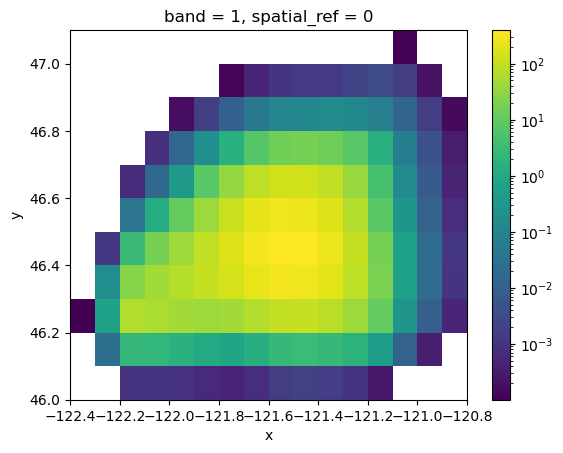

In [52]:
import matplotlib.colors as colors
f = f.where(f > 1e-4)
f = f.dropna(dim='x', how='all')
f = f.dropna(dim='y', how='all')
f.plot(norm=colors.LogNorm())